# Vessel data: SAIL ships on 22 August, 16:00-18:00

This notebook cleans the vessel position data (AIS and radar) and keeps only the SAIL ships in Amsterdam during our analysis period: Friday 22 August 2025, 16:00-18:00.

The raw file `Vesselposition_data_20-24Aug2025.csv` is 4.5 GB and too big for GitHub. Put it in `data/raw/` before running this notebook.

Author: Fabian

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data in chunks

The file has 12.6 million rows with ships along the whole Dutch coast. It does not fit in memory at once, so we read it in chunks of 1 million rows and only keep the sailing ships.

SAIL ships are the rows where:
- `type` is `SAIL`, or
- `sub-category` is `Sail Training Ship` or `Sailing Vessel`

In [2]:
file = "../data/raw/Vesselposition_data_20-24Aug2025.csv"
sail_sub = ["Sail Training Ship", "Sailing Vessel"]

parts = []
rows = 0
for chunk in pd.read_csv(file, chunksize=1_000_000, low_memory=False):
    rows += len(chunk)
    is_sail = (chunk["type"] == "SAIL") | (chunk["sub-category"].isin(sail_sub))
    parts.append(chunk[is_sail])

df_sail = pd.concat(parts, ignore_index=True)
print("rijen totaal:", rows)
print("rijen SAIL-schepen:", len(df_sail))

rijen totaal: 12641979
rijen SAIL-schepen: 226146


## 2. Select the time period

In [3]:
# de tijd staat in UTC, wij gebruiken Nederlandse tijd (net als de sensordata)
df_sail["timestamp"] = pd.to_datetime(df_sail["update-time"], utc=True).dt.tz_convert("Europe/Amsterdam")

start = pd.Timestamp("2025-08-22 16:00", tz="Europe/Amsterdam")
end = pd.Timestamp("2025-08-22 18:00", tz="Europe/Amsterdam")

df_sail = df_sail[(df_sail["timestamp"] >= start) & (df_sail["timestamp"] < end)].copy()
print("rijen in tijdvak:", len(df_sail))
print("schepen in tijdvak:", df_sail["name"].nunique())

rijen in tijdvak: 2664
schepen in tijdvak: 23


## 3. Select the area: Amsterdam

Some sailing ships are still on the North Sea Canal (near IJmuiden). We only keep the ships in the SAIL area in Amsterdam.

In [4]:
lon_min, lon_max = 4.85, 4.96
lat_min, lat_max = 52.365, 52.42

in_area = df_sail["lon"].between(lon_min, lon_max) & df_sail["lat"].between(lat_min, lat_max)

names_before = set(df_sail["name"].unique())
df_sail = df_sail[in_area].copy()
names_after = set(df_sail["name"].unique())

print("helemaal buiten Amsterdam:", list(names_before - names_after))
print("schepen in Amsterdam:", df_sail["name"].nunique())

helemaal buiten Amsterdam: ['JANTJE', 'GULDEN LEEUW', 'MORGENSTER']
schepen in Amsterdam: 20


## 4. Clean the data

In [5]:
print("oude berichten:", (df_sail["oud_bericht"] == True).sum())
print("zonder naam:", df_sail["name"].isna().sum())
print("dubbele regels:", df_sail.duplicated(subset=["name", "update-time"]).sum())

# oude berichten, schepen zonder naam en dubbele regels eruit
df_sail = df_sail[df_sail["oud_bericht"] == False]
df_sail = df_sail.dropna(subset=["name"])
df_sail = df_sail.drop_duplicates(subset=["name", "update-time"])

print("rijen over:", len(df_sail))

oude berichten: 19
zonder naam: 0
dubbele regels: 78
rijen over: 1567


In [6]:
# alleen de kolommen die we nodig hebben, met duidelijke namen en eenheden
df_ships = pd.DataFrame()
df_ships["timestamp"] = df_sail["timestamp"]
df_ships["name"] = df_sail["name"]
df_ships["category"] = df_sail["sub-category"].fillna("Sailing Vessel")
df_ships["length_m"] = df_sail["length"] / 100
df_ships["speed_ms"] = df_sail["speed-in-centimeters-per-second"] / 100
df_ships["lon"] = df_sail["lon"]
df_ships["lat"] = df_sail["lat"]

df_ships = df_ships.sort_values(["name", "timestamp"]).reset_index(drop=True)
df_ships.head()

,timestamp,name,category,length_m,speed_ms,lon,lat
0,2025-08-22 16:01:05+02:00,ALEXANDER VON HUMBOLDT II,Sail Training Ship,65.0,0.0,4.926961,52.376356
1,2025-08-22 16:02:38+02:00,ALEXANDER VON HUMBOLDT II,Sail Training Ship,65.0,0.0,4.926961,52.376356
2,2025-08-22 16:04:08+02:00,ALEXANDER VON HUMBOLDT II,Sail Training Ship,65.0,0.0,4.926961,52.376356
3,2025-08-22 16:27:26+02:00,ALEXANDER VON HUMBOLDT II,Sail Training Ship,65.0,0.0,4.926961,52.376347
4,2025-08-22 16:28:59+02:00,ALEXANDER VON HUMBOLDT II,Sail Training Ship,65.0,0.0,4.926961,52.376356


In [7]:
# rare waardes?
print("lengte:", df_ships["length_m"].min(), "tot", df_ships["length_m"].max(), "m")
print("snelheid:", df_ships["speed_ms"].min(), "tot", df_ships["speed_ms"].max(), "m/s")
print("lege waardes:", df_ships.isna().sum().sum())

lengte: 23.0 tot 115.0 m
snelheid: 0.0 tot 5.9 m/s
lege waardes: 0


## 5. Overview per ship

In [8]:
ships = {}
for name in df_ships["name"].unique():
    data = df_ships[df_ships["name"] == name]
    if data["speed_ms"].median() > 0.5:
        status = "sailing"
    else:
        status = "moored"
    ships[name] = {
        "length_m": data["length_m"].max(),
        "positions": len(data),
        "status": status,
    }

df_overview = pd.DataFrame(ships).T.sort_values("length_m", ascending=False)
df_overview

,length_m,positions,status
UNION,115.0,79,moored
DAR MLODZIEZY,108.0,78,moored
GORCH FOCK,81.0,60,moored
CHRISTIAN RADICH,73.0,58,moored
ALEXANDER VON HUMBOLDT II,65.0,58,moored
CAPITAN MIRANDA,64.0,78,moored
EENDRACHT,59.0,73,moored
BELEM,57.0,67,moored
EUROPA,56.0,76,moored
WYLDE SWAN,52.0,8,sailing


## 6. Map of the positions

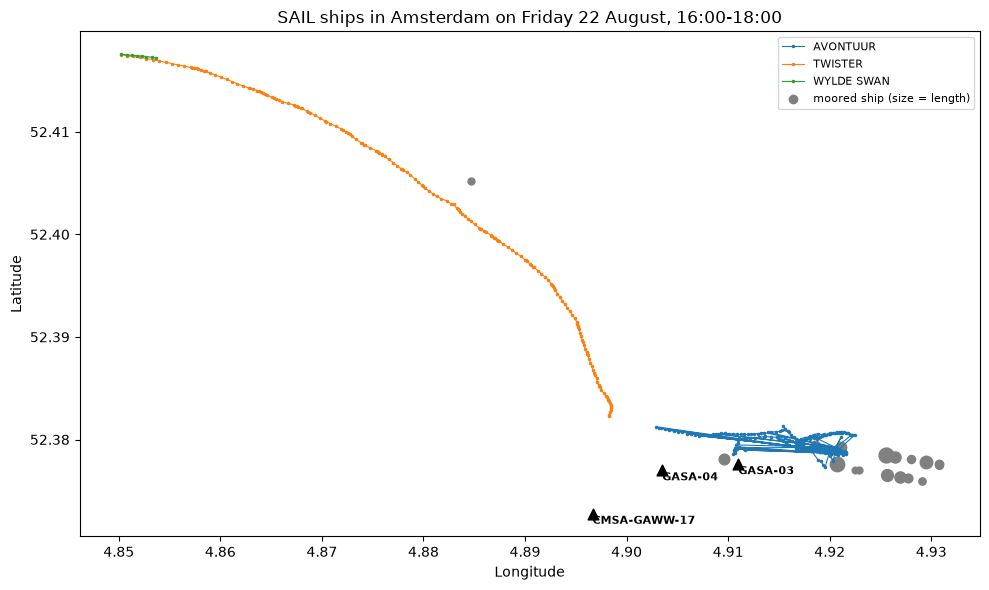

In [9]:
df_loc = pd.read_csv("../data/raw/sensor_locations.csv")
sensors = ["GASA-03", "GASA-04", "CMSA-GAWW-17"]

fig, ax = plt.subplots(figsize=(10, 6))
for name in df_ships["name"].unique():
    data = df_ships[df_ships["name"] == name]
    if ships[name]["status"] == "sailing":
        ax.plot(data["lon"], data["lat"], marker=".", markersize=3, linewidth=0.8, label=name)
    else:
        ax.scatter(data["lon"].iloc[-1], data["lat"].iloc[-1], color="grey", s=ships[name]["length_m"])

for sensor in sensors:
    row = df_loc[df_loc["Objectnummer"] == sensor]
    lat, lon = row["Lat/Long"].iloc[0].split(",")
    ax.scatter(float(lon), float(lat), color="black", marker="^", s=60)
    ax.text(float(lon), float(lat) - 0.001, sensor, fontsize=8, fontweight="bold")

ax.scatter([], [], color="grey", label="moored ship (size = length)")
ax.legend(fontsize=8)
ax.set_title("SAIL ships in Amsterdam on Friday 22 August, 16:00-18:00")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.savefig("../figures/sail_ships_22aug_16-18.png", dpi=150)
plt.show()

## 7. Save

In [10]:
df_ships.to_csv("../data/processed/sail_ships_22aug_16-18.csv", index=False)
print(df_ships.shape)

(1567, 7)
